In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

!pip install ucimlrepo


In [4]:

from ucimlrepo import fetch_ucirepo

# Fetch the dataset
real_estate = fetch_ucirepo(id=477)

# Get input features
X = real_estate.data.features

# Get target value
y = real_estate.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (414, 7)


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [5]:

print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()


First 5 rows:


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


Last 5 rows:


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5
413,2013.500,6.5,90.45606,9,24.97433,121.54310,63.9


Column names:
['X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   X1 transaction date                     414 non-null    float64
 1   X2 house age                            414 non-null    float64
 2   X3 distance to the nearest MRT station  414 non-null    float64
 3   X4 number of convenience stores         414 non-null    int64  
 4   X5 latitude                             414 non-null    float64
 5   X6 longitude                            414 non-null    float64
 6   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


In [6]:

print("Summary Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Summary Statistics:


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000



Missing Values:
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Duplicate Rows:
0


In [7]:

df.columns = [
    'Transaction_Date',
    'House_Age',
    'Distance_MRT',
    'Convenience_Stores',
    'Latitude',
    'Longitude',
    'House_Price'
]

print("Updated Column Names:")
print(df.columns.tolist())

display(df.head())


Updated Column Names:
['Transaction_Date', 'House_Age', 'Distance_MRT', 'Convenience_Stores', 'Latitude', 'Longitude', 'House_Price']


,Transaction_Date,House_Age,Distance_MRT,Convenience_Stores,Latitude,Longitude,House_Price
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [8]:

X = df.drop('House_Price', axis=1)

y = df['House_Price']

print("Input Features:")
display(X.head())

print("Target Variable:")
display(y.head())


Input Features:


,Transaction_Date,House_Age,Distance_MRT,Convenience_Stores,Latitude,Longitude
0,2012.917,32.0,84.87882,10,24.98298,121.54024
1,2012.917,19.5,306.59470,9,24.98034,121.53951
2,2013.583,13.3,561.98450,5,24.98746,121.54391
3,2013.500,13.3,561.98450,5,24.98746,121.54391
4,2012.833,5.0,390.56840,5,24.97937,121.54245


Target Variable:


,House_Price
0,37.9
1,42.2
2,47.3
3,54.8
4,43.1


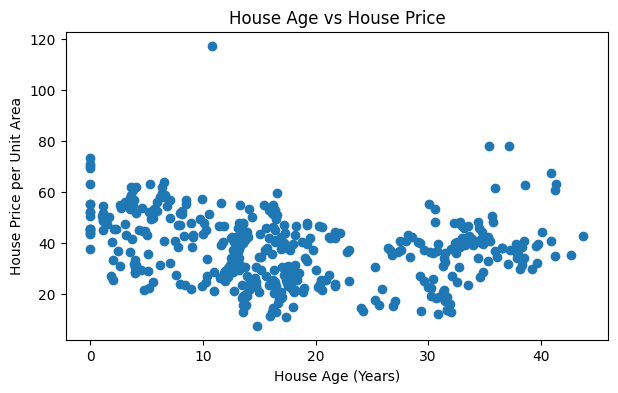

In [9]:

plt.figure(figsize=(7,4))

plt.scatter(df['House_Age'], df['House_Price'])

plt.title('House Age vs House Price')
plt.xlabel('House Age (Years)')
plt.ylabel('House Price per Unit Area')

plt.show()


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (331, 6)
Testing data: (83, 6)


In [11]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [12]:

print("Model Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)


Model Intercept:
-13044.231917160534

Model Coefficients:
Transaction_Date : 5.44074185669585
House_Age : -0.2707914899624964
Distance_MRT : -0.004758638917293889
Convenience_Stores : 1.091425267691969
Latitude : 229.04305381550026
Longitude : -29.492590776198245


In [13]:

y_pred = model.predict(X_test)

print("House Price Predictions:")


House Price Predictions:


In [14]:

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

display(comparison.head(10))


,Actual Price,Predicted Price
0,45.1,47.886254
1,42.3,41.164046
2,52.2,44.273014
3,37.3,40.197615
4,22.8,27.513265
5,36.3,45.109531
6,53.0,44.632933
7,51.4,46.363462
8,16.1,23.620631
9,59.0,54.334449


In [15]:

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)

print("Mean Squared Error (MSE):", mse)

print("Root Mean Squared Error (RMSE):", rmse)

print("R2 Score:", r2)


Mean Absolute Error (MAE): 5.305355690074184
Mean Squared Error (MSE): 53.505619124504506
Root Mean Squared Error (RMSE): 7.314753524521828
R2 Score: 0.6810580555095801


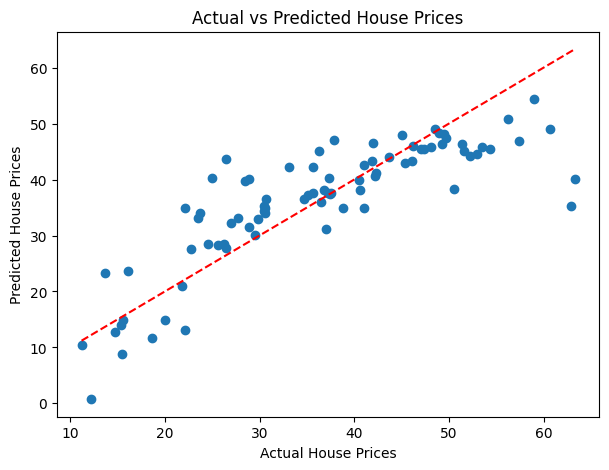

In [16]:

plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')

plt.show()


In [17]:

new_house = pd.DataFrame([{
    'Transaction_Date': 2013.5,
    'House_Age': 10,
    'Distance_MRT': 500,
    'Convenience_Stores': 5,
    'Latitude': 24.98,
    'Longitude': 121.54
}])

predicted_price = model.predict(new_house)

print("Predicted House Price per Unit Area:")
print(predicted_price[0])

print("Unit: 10,000 New Taiwan Dollars per Ping")


Predicted House Price per Unit Area:
48.03770464881018
Unit: 10,000 New Taiwan Dollars per Ping


## Conclusion

The Real Estate Valuation dataset was used to develop a house price prediction model. The dataset was loaded and inspected using Python. Input features and the target variable were selected. The data was divided into training and testing sets in an 80:20 ratio. Linear Regression was trained using the training data. Predictions were generated and evaluated using MAE, MSE, RMSE and R² score. Graphs were also created to compare actual and predicted prices.

Thus, Linear Regression was successfully implemented for house price prediction.